In [30]:
import pandas as pd

In [31]:
df=pd.read_csv(r"D:\xwechat_files\wxid_paj042r7j8kg22_0c39\msg\file\2026-11\rent_raw.csv",encoding="utf-8-sig")

In [32]:
df.head()

,城市,区,小区,价格,面积,室,厅,卫,朝向
0,北京,海淀,上地西里,15000,137,3,2,2,南北
1,北京,丰台,电报局街,4500,57,2,1,1,南北
2,北京,朝阳,远洋新干线,10500,56,1,1,1,北
3,北京,西城,南露园,5600,43,1,1,1,东
4,北京,朝阳,和平里东街15号院,6300,56,2,1,1,东南


In [33]:
df.columns

Index(['城市', '区', '小区', '价格', '面积', '室', '厅', '卫', '朝向'], dtype='str')

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   城市      12000 non-null  str  
 1   区       12000 non-null  str  
 2   小区      10486 non-null  str  
 3   价格      12000 non-null  str  
 4   面积      12000 non-null  str  
 5   室       12000 non-null  int64
 6   厅       12000 non-null  int64
 7   卫       12000 non-null  int64
 8   朝向      11899 non-null  str  
dtypes: int64(3), str(6)
memory usage: 1.3 MB


In [35]:
df.describe()

,室,厅,卫
count,12000.000000,12000.000000,12000.000000
mean,2.242667,1.228167,1.332583
std,1.161849,0.672169,0.682161
min,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.000000
50%,2.000000,1.000000,1.000000
75%,3.000000,2.000000,2.000000
max,20.000000,5.000000,9.000000


In [36]:
df.isnull().sum()

城市       0
区        0
小区    1514
价格       0
面积       0
室        0
厅        0
卫        0
朝向     101
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(67)

In [38]:
df=df.drop_duplicates()

In [39]:
print(df.columns.tolist())

['城市', '区', '小区', '价格', '面积', '室', '厅', '卫', '朝向']


In [40]:
# 清洗价格
df["价格"] = df["价格"].str.replace("元/月","", regex=False)
df["价格"] = pd.to_numeric(df["价格"], errors="coerce")

# 清洗面积
df["面积"] = df["面积"].str.replace("㎡","", regex=False)
df["面积"] = pd.to_numeric(df["面积"], errors="coerce")

In [41]:
print(df[["价格","面积"]].isna().sum())

价格    523
面积    250
dtype: int64


In [42]:
# 整体统计：均值、最大最小、分位数
df[["价格","面积"]].describe()
# 看各区房源数量、均价，快速抓业务直观信息
df.groupby("区")["价格"].agg(["count","mean"])

,count,mean
区,,
东城,64,8948.437500
丰台,319,7208.912226
亦庄开发区,56,7243.750000
从化,21,1895.238095
光明区,56,2905.160714
南山区,552,12294.161232
南沙,47,2341.702128
嘉定,188,4978.441489
坪山区,9,2186.666667


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.sans-serif"] = ["SimHei"] # 解决中文乱码
plt.rcParams["axes.unicode_minus"] = False

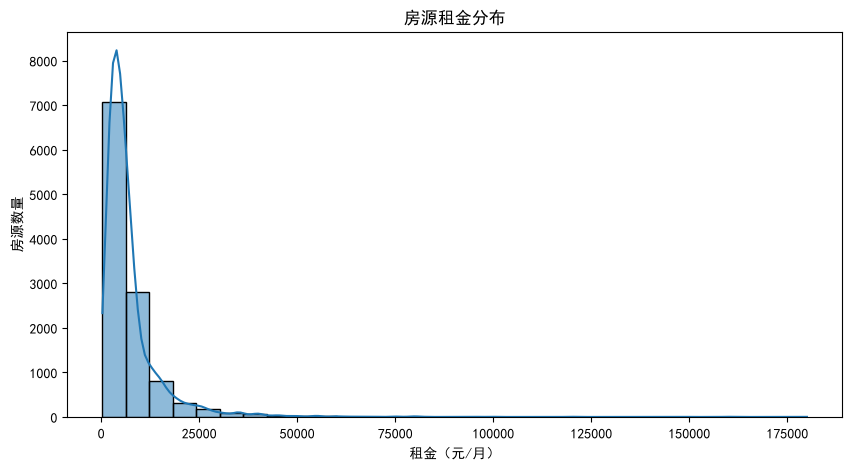

In [44]:
# 1. 租金分布直方图，看大部分房租集中区间
plt.figure(figsize=(10,5))
sns.histplot(df["价格"], bins=30, kde=True)
plt.title("房源租金分布")
plt.xlabel("租金（元/月）")
plt.ylabel("房源数量")
plt.show()

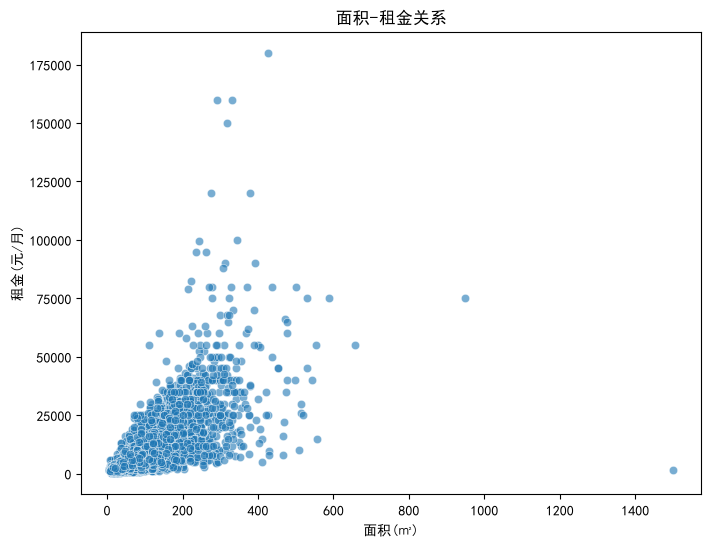

In [45]:
# 2. 面积和租金散点图，看相关性
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="面积", y="价格", alpha=0.6)
plt.title("面积-租金关系")
plt.xlabel("面积(㎡)")
plt.ylabel("租金(元/月)")
plt.show()


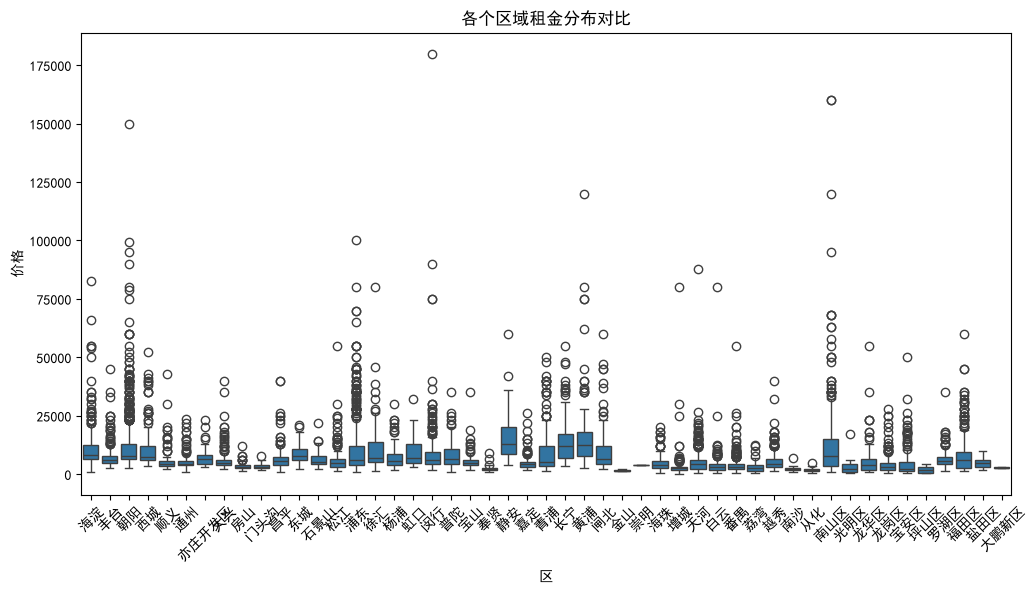

In [46]:
# 3. 不同行政区租金箱线图
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="区", y="价格")
plt.title("各个区域租金分布对比")
plt.xticks(rotation=45) # 区名字太长，旋转45度防止重叠
plt.show()


In [47]:
df["单价_每平"] = df["价格"] / df["面积"]


In [48]:
df.groupby("区")["单价_每平"].agg(["count","mean"]).sort_values("mean",ascending=False)


,count,mean
区,,
静安,91,155.634997
黄浦,111,145.404378
福田区,465,144.717798
南山区,550,142.618414
东城,64,138.792285
西城,201,135.012752
长宁,180,133.865371
徐汇,215,125.917802
海淀,330,120.889300


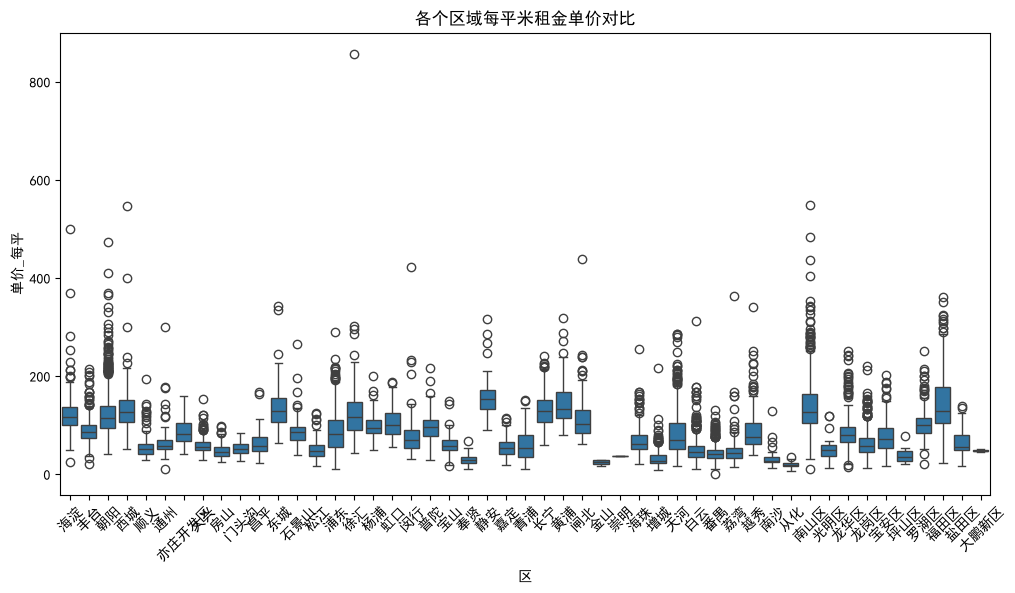

In [49]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="区", y="单价_每平")
plt.title("各个区域每平米租金单价对比")
plt.xticks(rotation=45)
plt.show()


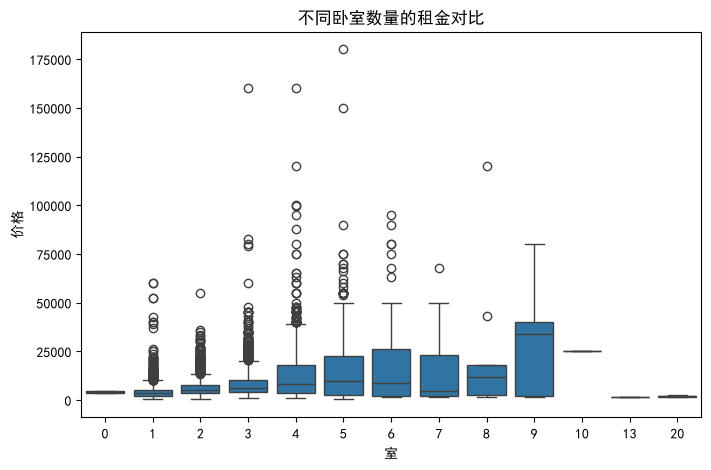

In [50]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="室", y="价格")
plt.title("不同卧室数量的租金对比")
plt.show()

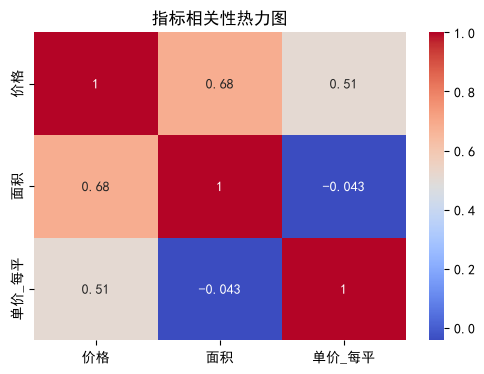

In [51]:
plt.figure(figsize=(6,4))
corr = df[["价格","面积","单价_每平"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("指标相关性热力图")
plt.show()


In [52]:
# 以价格为例，剔除极端高价异常值
Q1 = df["价格"].quantile(0.25)
Q3 = df["价格"].quantile(0.75)
IQR = Q3 - Q1
df_filter = df[(df["价格"] >= Q1 - 1.5*IQR) & (df["价格"] <= Q3 + 1.5*IQR)]
print("过滤前：", len(df))
print("过滤后：", len(df_filter))

过滤前： 11933
过滤后： 10367


In [53]:
!pip install pymysql


In [54]:
import pandas as pd
from sqlalchemy import create_engine

user = "root"
password = "123456"
host = "127.0.0.1"
port = 3306
db_name = "rent_data"

engine = create_engine(f'mysql+pymysql://{user}:{password}@{host}:{port}/{db_name}?charset=utf8mb4')

df.to_sql(
    name="house",
    con=engine,
    index=False,
    if_exists="replace",
    chunksize=1000
)
print("写入成功！")

test_df = pd.read_sql("select * from house limit 5;", engine)
display(test_df)


写入成功！


,城市,区,小区,价格,面积,室,厅,卫,朝向,单价_每平
0,北京,海淀,上地西里,15000.0,137.0,3,2,2,南北,109.489051
1,北京,丰台,电报局街,4500.0,57.0,2,1,1,南北,78.947368
2,北京,朝阳,远洋新干线,10500.0,56.0,1,1,1,北,187.500000
3,北京,西城,南露园,5600.0,43.0,1,1,1,东,130.232558
4,北京,朝阳,和平里东街15号院,6300.0,56.0,2,1,1,东南,112.500000


In [56]:
df.head()


,城市,区,小区,价格,面积,室,厅,卫,朝向,单价_每平
0,北京,海淀,上地西里,15000.0,137.0,3,2,2,南北,109.489051
1,北京,丰台,电报局街,4500.0,57.0,2,1,1,南北,78.947368
2,北京,朝阳,远洋新干线,10500.0,56.0,1,1,1,北,187.500000
3,北京,西城,南露园,5600.0,43.0,1,1,1,东,130.232558
4,北京,朝阳,和平里东街15号院,6300.0,56.0,2,1,1,东南,112.500000
